# 04 · Adaptive vs static comparison

Created by `scripts/compare_adaptive.py` (Step 4). All methods use the **same trial budget**, folds and seed.

| Method | Meaning |
|---|---|
| B2_static | Optuna TPE, all families, fixed ranges, 1 round |
| A_full | adaptive loop (your method) |
| A_no_ranges | ablation: ranges never change |
| A_no_families | ablation: no family is dropped |

In [1]:
import json, ast, glob
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

from c2_automl.config import OUTPUT_DIR
from c2_automl.io.dummy_c1 import load_c1_output, load_split

# Validated light palette (same colours as the dashboard)
FAMILY_COLORS = {"random_forest": "#2a78d6", "xgboost": "#eb6834", "lightgbm": "#1baf7a",
                 "catboost": "#eda100", "logistic_regression": "#e87ba4", "ridge": "#008300"}
ROUND_COLORS = {1: "#86b6ef", 2: "#3987e5", 3: "#184f95", 4: "#0d366b"}
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
                     "axes.edgecolor": "#c3c2b7", "axes.grid": True, "grid.color": "#e1e0d9",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.labelcolor": "#52514e", "xtick.color": "#898781", "ytick.color": "#898781",
                     "font.size": 10, "lines.linewidth": 2})

In [2]:
files = sorted(glob.glob(str(OUTPUT_DIR / "*" / "comparison_*.csv")))
df = pd.concat([pd.read_csv(f).assign(dataset=Path(f).parent.name) for f in files], ignore_index=True)
cols = ["dataset", "method", "seed", "family", "rounds", "trials", "best_cv", "roc_auc", "f1", "recall", "precision", "time_s"]
df[[c for c in cols if c in df.columns]].round(4)

,dataset,method,seed,family,rounds,trials,best_cv,roc_auc,f1,recall,precision,time_s
0,adult_imbalanced,B2_static,42,catboost,1,90,0.9215,0.9207,0.4027,0.2609,0.8824,140.9
1,adult_imbalanced,A_full,42,xgboost,3,90,0.9204,0.9257,0.4355,0.3304,0.6387,225.5
2,adult_imbalanced,A_no_ranges,42,xgboost,3,90,0.9208,0.9265,0.3806,0.2391,0.9322,226.9
3,adult_imbalanced,A_no_families,42,xgboost,3,90,0.9204,0.9257,0.4355,0.3304,0.6387,171.6
4,diabetes,B2_static,42,catboost,1,90,0.8377,0.8248,0.5625,0.5000,0.6429,59.3
5,diabetes,A_full,42,catboost,3,90,0.8367,0.8230,0.6337,0.5926,0.6809,59.5
6,diabetes,A_no_ranges,42,catboost,3,90,0.8368,0.8196,0.6061,0.5556,0.6667,85.6
7,diabetes,A_no_families,42,catboost,3,90,0.8367,0.8230,0.6337,0.5926,0.6809,71.2


## Hold-out metrics per method
For imbalanced data, **recall** and **F1** show whether the rare class is found.

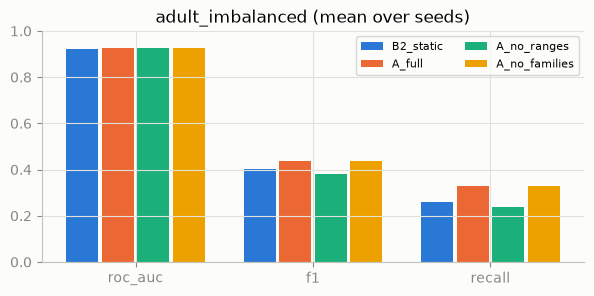

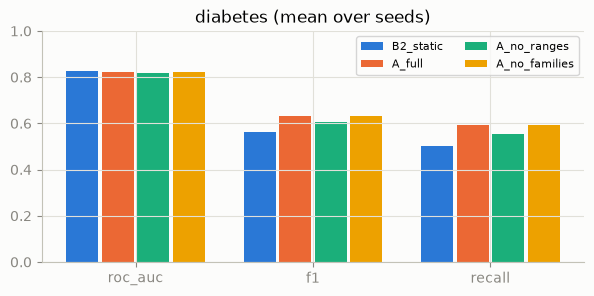

In [3]:
METHOD_COLORS = {"B2_static": "#2a78d6", "A_full": "#eb6834", "A_no_ranges": "#1baf7a", "A_no_families": "#eda100"}
metrics = ["roc_auc", "f1", "recall"]
for dataset, d in df.groupby("dataset"):
    m = d.groupby("method")[metrics].mean().reindex([k for k in METHOD_COLORS if k in set(d.method)])
    fig, ax = plt.subplots(figsize=(7, 3))
    width = 0.8 / len(m)
    for i, (method, row) in enumerate(m.iterrows()):
        ax.bar([x + i * width for x in range(len(metrics))], row.values, width=width * 0.9,
               color=METHOD_COLORS[method], label=method)
    ax.set_xticks([x + width * (len(m) - 1) / 2 for x in range(len(metrics))], metrics)
    ax.set_ylim(0, 1); ax.set_title(f"{dataset} (mean over seeds)"); ax.legend(fontsize=8, ncol=2); plt.show()

## Statistical test (when you have several seeds)
Wilcoxon signed-rank test, paired by (dataset, seed). Needs `--seeds 5` or more to be meaningful.

In [4]:
from scipy.stats import wilcoxon

paired = df.pivot_table(index=["dataset", "seed"], columns="method", values="recall")
if {"A_full", "B2_static"} <= set(paired.columns) and len(paired) >= 5:
    print(wilcoxon(paired["A_full"], paired["B2_static"]))
else:
    print(f"Only {len(paired)} paired results - run compare_adaptive.py with --seeds 5 on several datasets first.")

Only 2 paired results - run compare_adaptive.py with --seeds 5 on several datasets first.
